In [2]:
# Veriyi okuma ve işleme adımında kullanılacak olan kütüphaneler

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import tensorflow as tf


# Model değelendirme ve veriyi scale edebilmemiz için kullanılacak olan kütüphaneler

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error


# Model için kullanılacak olan kütüphaneler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Warningleri kapatmak içib kullanılmaktadır
import warnings
warnings.filterwarnings('ignore')


# Tensorflow Warning engelleme
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)

In [3]:
df = pd.read_csv('international-airline-passengers.csv')
df.head()

,Month,International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60
0,1949-01,112.0
1,1949-02,118.0
2,1949-03,132.0
3,1949-04,129.0
4,1949-05,121.0


In [4]:
df.columns


Index(['Month', 'International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60'], dtype='object')

In [5]:
df.columns = ["Month","Passengers"]

In [6]:
df.columns


Index(['Month', 'Passengers'], dtype='object')

In [7]:
df.shape



(145, 2)

In [8]:
df.dtypes

Month          object
Passengers    float64
dtype: object

In [9]:
df.tail()

,Month,Passengers
140,1960-09,508.0
141,1960-10,461.0
142,1960-11,390.0
143,1960-12,432.0
144,International airline passengers: monthly tota...,NaN


In [10]:
df.isnull().sum()

Month         0
Passengers    1
dtype: int64

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Passengers,144.0,280.298611,119.966317,104.0,180.0,265.5,360.5,622.0


In [14]:
df = df[:144]

In [15]:
df.tail()

,Month,Passengers
139,1960-08,606.0
140,1960-09,508.0
141,1960-10,461.0
142,1960-11,390.0
143,1960-12,432.0


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Month       144 non-null    object 
 1   Passengers  144 non-null    float64
dtypes: float64(1), object(1)
memory usage: 2.4+ KB


In [18]:
df["Month"] = pd.to_datetime(df["Month"])

In [19]:
print("minimum tarih:" , df["Month"].min())
print("maximum tarih:" , df["Month"].max())


minimum tarih: 1949-01-01 00:00:00
maximum tarih: 1960-12-01 00:00:00


In [20]:
df.head()

,Month,Passengers
0,1949-01-01,112.0
1,1949-02-01,118.0
2,1949-03-01,132.0
3,1949-04-01,129.0
4,1949-05-01,121.0


In [21]:
df.index = df ["Month"]

In [22]:
df.head()

,Month,Passengers
Month,,
1949-01-01,1949-01-01,112.0
1949-02-01,1949-02-01,118.0
1949-03-01,1949-03-01,132.0
1949-04-01,1949-04-01,129.0
1949-05-01,1949-05-01,121.0


In [23]:
df.drop("Month",axis = 1 , inplace = True)

In [24]:
df.head()

,Passengers
Month,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0


In [25]:
result_df = df.copy()

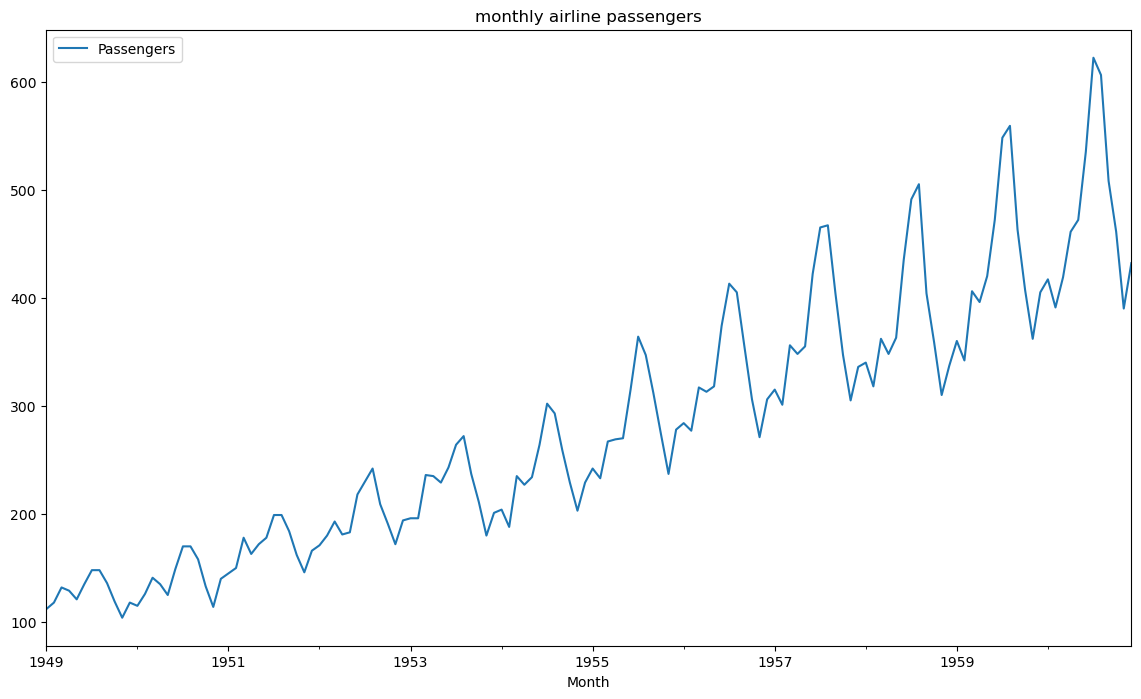

In [26]:
df.plot (figsize=(14,8), title = "monthly airline passengers");

In [27]:
data = df["Passengers"].values

In [28]:
data[0:5]

array([112., 118., 132., 129., 121.])

In [29]:
data.shape

(144,)

In [30]:
data = data.reshape(-1,1)

In [31]:
data.shape

(144, 1)

In [ ]:
# train ve test seti olarak ayırma 


In [32]:
def split_data (dataframe , test_size ) : 
    position = int (round (len (dataframe)*(1-test_size)))
    train = dataframe [:position]
    test = dataframe [position:]
    return train , test , position 

In [33]:
train, test , position = split_data (data, 0.33)

In [34]:
print (train.shape,test.shape)

(96, 1) (48, 1)
